# AutoVision AI - Make & Model Classifier Training

Fine-tunes **MobileNetV3-Large** (ImageNet pretrained) on **Stanford Cars** (196 make/model/year classes,
8,144 train / 8,041 test images) for the fine-grained classification stage of AutoVision AI.

Outputs: `models/car_classifier.pt` and `models/class_names.json`, which `app.py` loads.

Edge-case augmentation (night, glare, rain/motion blur) is included to match real dashcam/webcam footage.

In [1]:
import json, math, random, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights
from datasets import load_dataset

torch.manual_seed(42); random.seed(42); np.random.seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

MODELS_DIR = Path("models"); MODELS_DIR.mkdir(exist_ok=True)
EPOCHS = 30
WARMUP_EPOCHS = 2      # head-only training before unfreezing the backbone
BATCH_SIZE = 64
LR = 1e-3
IMG_SIZE = 224

C:\CollegeWork\ML\MiniProject\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda NVIDIA GeForce RTX 3050 6GB Laptop GPU


## 1. Load Stanford Cars
The original Stanford download link is dead, so we use the Hugging Face mirror.

In [2]:
ds = load_dataset("tanganke/stanford_cars")
print(ds)
class_names = ds["train"].features["label"].names
print(len(class_names), "classes, e.g.", class_names[:5])

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 8144
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 8041
    })
    contrast: Dataset({
        features: ['image', 'label'],
        num_rows: 8041
    })
    gaussian_noise: Dataset({
        features: ['image', 'label'],
        num_rows: 8041
    })
    impulse_noise: Dataset({
        features: ['image', 'label'],
        num_rows: 8041
    })
    jpeg_compression: Dataset({
        features: ['image', 'label'],
        num_rows: 8041
    })
    motion_blur: Dataset({
        features: ['image', 'label'],
        num_rows: 8041
    })
    pixelate: Dataset({
        features: ['image', 'label'],
        num_rows: 8041
    })
    spatter: Dataset({
        features: ['image', 'label'],
        num_rows: 8041
    })
})
196 classes, e.g. ['AM General Hummer SUV 2000', 'Acura RL Sedan 2012', 'Acura TL Sedan 2012', 'Acura TL Type-S 2008', 'Acura TSX Sedan 2012'

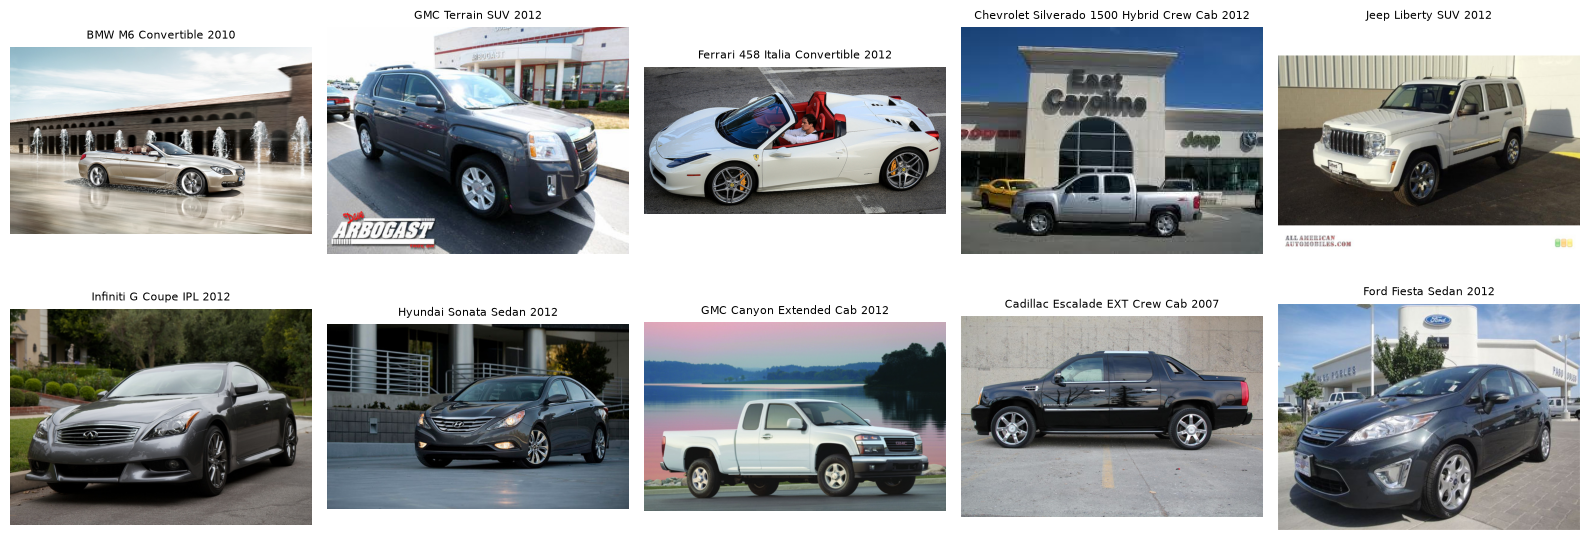

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, i in zip(axes.flat, random.sample(range(len(ds["train"])), 10)):
    ex = ds["train"][i]
    ax.imshow(ex["image"]); ax.set_title(class_names[ex["label"]], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Augmentation (incl. day/night, glare and rain edge cases)

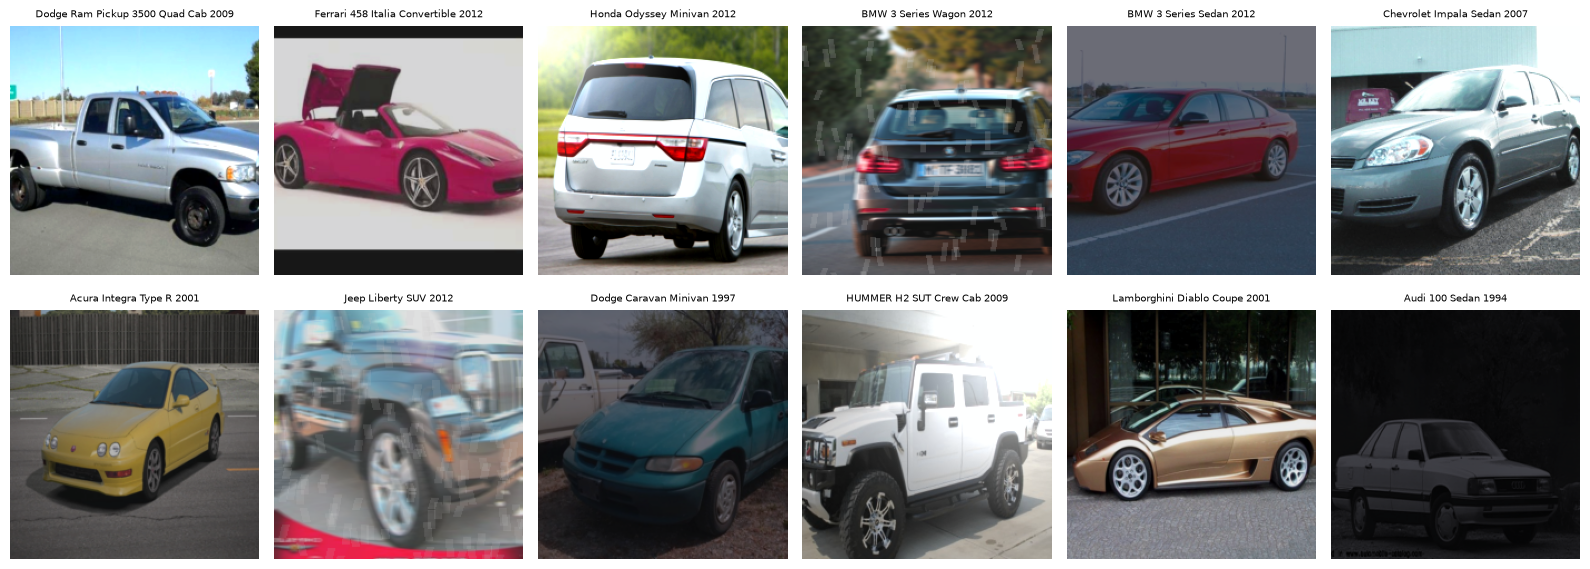

In [4]:
class EdgeCaseAug:
    """Randomly simulates night, sun glare or rain/motion blur on a PIL image."""
    def __init__(self, p=0.4):
        self.p = p

    def __call__(self, img):
        if random.random() > self.p:
            return img
        x = np.asarray(img).astype(np.float32)
        h, w = x.shape[:2]
        kind = random.choice(["night", "glare", "rain"])
        if kind == "night":
            x = x * random.uniform(0.25, 0.55)
            x[..., 2] *= 1.1  # slight blue tint
        elif kind == "glare":
            cy, cx = random.randint(0, h // 2), random.randint(0, w - 1)
            yy, xx = np.ogrid[:h, :w]
            r = random.uniform(0.2, 0.5) * max(h, w)
            blob = np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / (2 * r ** 2))[..., None]
            x = x + blob * 220
        else:  # rain: streaks + motion blur
            import cv2
            for _ in range(random.randint(80, 200)):
                x0, y0 = random.randint(0, w - 1), random.randint(0, h - 1)
                cv2.line(x, (x0, y0), (x0 + random.randint(-3, 3), y0 + random.randint(8, 18)), (200, 200, 200), 1)
            k = random.choice([5, 7, 9])
            kernel = np.zeros((k, k), np.float32); kernel[k // 2, :] = 1 / k
            x = cv2.filter2D(x, -1, kernel)
        return T.functional.to_pil_image(np.clip(x, 0, 255).astype(np.uint8))

normalize = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.75, 1.6)),
    T.RandomHorizontalFlip(),
    T.ColorJitter(0.3, 0.3, 0.3, 0.05),
    EdgeCaseAug(p=0.4),
    T.ToTensor(), normalize,
])
# The app squeezes each detected car crop to 224x224, so test the same way
test_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), normalize])

class HFDataset(Dataset):
    def __init__(self, split, tf):
        self.split, self.tf = split, tf
    def __len__(self):
        return len(self.split)
    def __getitem__(self, i):
        ex = self.split[i]
        return self.tf(ex["image"].convert("RGB")), ex["label"]

train_dl = DataLoader(HFDataset(ds["train"], train_tf), batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
test_dl = DataLoader(HFDataset(ds["test"], test_tf), batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

# Preview augmented samples
xb, yb = next(iter(train_dl))
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, x, y in zip(axes.flat, xb, yb):
    img = (x.permute(1, 2, 0).numpy() * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]).clip(0, 1)
    ax.imshow(img); ax.set_title(class_names[y], fontsize=7); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Model: MobileNetV3-Large with a 196-way head

In [5]:
model = mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.IMAGENET1K_V2)
model.classifier[3] = nn.Linear(model.classifier[3].in_features, len(class_names))
model = model.to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M")

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.02)
steps = EPOCHS * len(train_dl)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, total_steps=steps, pct_start=0.1)
scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")

def set_backbone_trainable(flag):
    for p in model.features.parameters():
        p.requires_grad = flag

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to C:\Users\Lenovo/.cache\torch\hub\checkpoints\mobilenet_v3_large-5c1a4163.pth


  0%|          | 0.00/21.1M [00:00<?, ?B/s]

 21%|██        | 4.38M/21.1M [00:00<00:00, 45.7MB/s]

 48%|████▊     | 10.1M/21.1M [00:00<00:00, 54.2MB/s]

 82%|████████▏ | 17.2M/21.1M [00:00<00:00, 63.3MB/s]

100%|██████████| 21.1M/21.1M [00:00<00:00, 63.3MB/s]

Parameters: 4.45 M


## 4. Training

In [6]:
@torch.no_grad()
def evaluate(loader):
    model.eval()
    correct1 = correct5 = n = 0
    loss_sum = 0.0
    preds, labels = [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            logits = model(x)
            loss_sum += criterion(logits, y).item() * len(y)
        top5 = logits.topk(5, dim=1).indices
        correct1 += (top5[:, 0] == y).sum().item()
        correct5 += (top5 == y[:, None]).any(dim=1).sum().item()
        n += len(y)
        preds.append(top5[:, 0].cpu()); labels.append(y.cpu())
    return loss_sum / n, correct1 / n, correct5 / n, torch.cat(preds).numpy(), torch.cat(labels).numpy()

history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
best_acc = 0.0
for epoch in range(EPOCHS):
    set_backbone_trainable(epoch >= WARMUP_EPOCHS)
    model.train()
    t0, loss_sum, correct, n = time.time(), 0.0, 0, 0
    for x, y in train_dl:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            logits = model(x)
            loss = criterion(logits, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update(); scheduler.step()
        loss_sum += loss.item() * len(y); correct += (logits.argmax(1) == y).sum().item(); n += len(y)

    test_loss, top1, top5, _, _ = evaluate(test_dl)
    history["train_loss"].append(loss_sum / n); history["train_acc"].append(correct / n)
    history["test_loss"].append(test_loss); history["test_acc"].append(top1)
    flag = ""
    if top1 > best_acc:
        best_acc = top1
        torch.save(model.state_dict(), MODELS_DIR / "car_classifier.pt")
        flag = "  <- saved"
    line = (f"Epoch {epoch + 1:2d}/{EPOCHS}  train loss {loss_sum / n:.3f} acc {correct / n:.3f}  "
            f"test loss {test_loss:.3f} top1 {top1:.3f} top5 {top5:.3f}  ({time.time() - t0:.0f}s){flag}")
    print(line)
    with open(MODELS_DIR / "train_log.txt", "a") as f:
        f.write(line + "\n")

(MODELS_DIR / "class_names.json").write_text(json.dumps(class_names, indent=1), encoding="utf-8")
print(f"Best test Top-1: {best_acc:.3f}")

Epoch  1/30  train loss 5.241 acc 0.016  test loss 5.079 top1 0.047 top5 0.170  (147s)  <- saved


Epoch  2/30  train loss 4.698 acc 0.100  test loss 4.098 top1 0.172 top5 0.405  (144s)  <- saved


Epoch  3/30  train loss 3.024 acc 0.410  test loss 3.110 top1 0.365 top5 0.697  (167s)  <- saved


Epoch  4/30  train loss 1.974 acc 0.704  test loss 2.222 top1 0.617 top5 0.881  (193s)  <- saved


Epoch  5/30  train loss 1.584 acc 0.832  test loss 2.241 top1 0.641 top5 0.875  (173s)  <- saved


Epoch  6/30  train loss 1.406 acc 0.884  test loss 1.905 top1 0.726 top5 0.928  (142s)  <- saved


... (20 outputs left out)

Epoch 27/30  train loss 0.928 acc 0.997  test loss 1.410 top1 0.886 top5 0.976  (135s)


Epoch 28/30  train loss 0.925 acc 0.997  test loss 1.408 top1 0.887 top5 0.975  (136s)


Epoch 29/30  train loss 0.928 acc 0.996  test loss 1.407 top1 0.887 top5 0.976  (136s)


Epoch 30/30  train loss 0.927 acc 0.997  test loss 1.409 top1 0.888 top5 0.976  (136s)  <- saved
Best test Top-1: 0.888


## 5. Evaluation

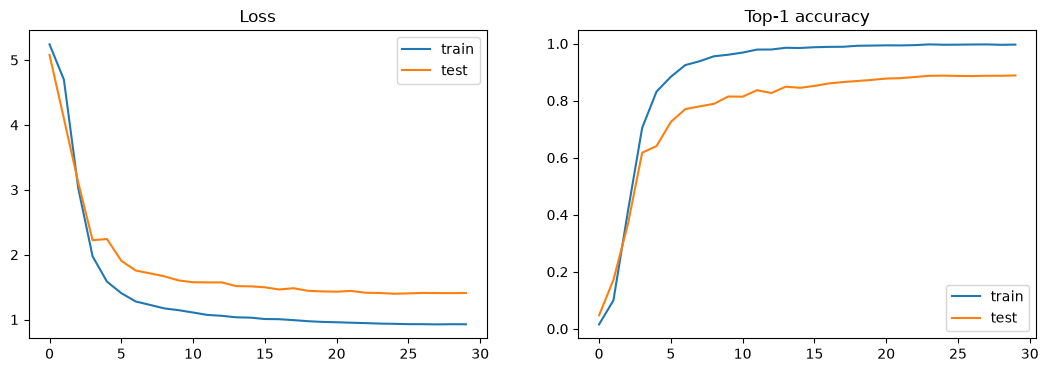

Final test  Top-1: 88.84%   Top-5: 97.57%


78

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.plot(history["train_loss"], label="train"); a1.plot(history["test_loss"], label="test"); a1.set_title("Loss"); a1.legend()
a2.plot(history["train_acc"], label="train"); a2.plot(history["test_acc"], label="test"); a2.set_title("Top-1 accuracy"); a2.legend()
plt.show()

model.load_state_dict(torch.load(MODELS_DIR / "car_classifier.pt", weights_only=True))
test_loss, top1, top5, preds, labels = evaluate(test_dl)
print(f"Final test  Top-1: {top1 * 100:.2f}%   Top-5: {top5 * 100:.2f}%")
(MODELS_DIR / "metrics.json").write_text(json.dumps({"top1": top1, "top5": top5, "epochs": EPOCHS}, indent=2))

In [8]:
# Make-level accuracy (is the brand right even if the exact model/year is wrong?)
import sys; sys.path.insert(0, ".")
from autovision.specs import lookup
makes = np.array([lookup(c).make for c in class_names])
print(f"Make-level accuracy: {(makes[preds] == makes[labels]).mean() * 100:.2f}%")

# Most confused class pairs
from collections import Counter
pairs = Counter((class_names[l], class_names[p]) for p, l in zip(preds, labels) if p != l)
for (true, pred), c in pairs.most_common(10):
    print(f"{c:3d}x  {true}  ->  {pred}")

Make-level accuracy: 94.45%
 14x  Dodge Sprinter Cargo Van 2009  ->  Mercedes-Benz Sprinter Van 2012
 11x  Bentley Continental GT Coupe 2012  ->  Bentley Continental GT Coupe 2007
 10x  Audi V8 Sedan 1994  ->  Audi 100 Sedan 1994
 10x  Audi 100 Sedan 1994  ->  Audi V8 Sedan 1994
 10x  BMW 6 Series Convertible 2007  ->  BMW M6 Convertible 2010
 10x  Chevrolet Express Van 2007  ->  Chevrolet Express Cargo Van 2007
 10x  Chevrolet Express Van 2007  ->  GMC Savana Van 2012
 10x  Dodge Caliber Wagon 2012  ->  Dodge Caliber Wagon 2007
  9x  Audi TTS Coupe 2012  ->  Audi TT Hatchback 2011
  9x  Audi TT Hatchback 2011  ->  Audi TT RS Coupe 2012


In [9]:
# Per-class accuracy: best and worst classes
per_class = np.array([(preds[labels == k] == k).mean() for k in range(len(class_names))])
order = per_class.argsort()
print("Hardest classes:"); [print(f"  {per_class[k] * 100:5.1f}%  {class_names[k]}") for k in order[:8]]
print("Easiest classes:"); [print(f"  {per_class[k] * 100:5.1f}%  {class_names[k]}") for k in order[-8:]]

Hardest classes:
   42.9%  Chevrolet Express Van 2007
   44.8%  Chevrolet Express Cargo Van 2007
   52.5%  Audi TT Hatchback 2011
   59.0%  Dodge Sprinter Cargo Van 2009
   59.5%  Audi TTS Coupe 2012
   61.0%  Aston Martin V8 Vantage Coupe 2012
   62.5%  Audi 100 Sedan 1994
   64.3%  Audi 100 Wagon 1994
Easiest classes:
  100.0%  Fisker Karma Sedan 2012
  100.0%  Ford F-450 Super Duty Crew Cab 2012
  100.0%  Ford Edge SUV 2012
  100.0%  Land Rover Range Rover SUV 2012
  100.0%  Volkswagen Beetle Hatchback 2012
  100.0%  Toyota 4Runner SUV 2012
  100.0%  Hyundai Veloster Hatchback 2012
  100.0%  smart fortwo Convertible 2012


[None, None, None, None, None, None, None, None]